# Initialized

## Import Library

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

## Device Keras

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Status Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

Status Device: cuda
GPU Model: NVIDIA GeForce RTX 4060 Laptop GPU


## Set Seed

Mengunci Seed di awal untuk memenuhi permintaan soal "Seluruh model generatif wajib dilatih menggunakan dataset yang sama, train-val-test split yang seragam, serta penetapan random seed yang tetap (misalnya: torch.manual_seed(42) dan np.random.seed(42))"

In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Load Data MNIST

## Normalize
Dari rentang [0, 1] ke [-1, 1] agar sesuai aktivasi dengan tanh

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

## Download Dataset

In [5]:
# Download dataset
raw_train = datasets.MNIST(root="./data", train=True, transform=transform, download=True)
raw_test = datasets.MNIST(root="./data", train=False, transform=transform, download=True)
full_dataset = torch.utils.data.ConcatDataset([raw_train, raw_test])

## Data Splitting

In [6]:
total_len = len(full_dataset)
train_size = int(0.80 * total_len)
val_size = int(0.10 * total_len)   
test_size = total_len - train_size - val_size 

train_set, val_set, test_set = torch.utils.data.random_split(
    full_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

In [7]:
print(f"- Train Set : {len(train_set)} Images")
print(f"- Val Set   : {len(val_set)} Images")
print(f"- Test Set  : {len(test_set)} Images")

- Train Set : 56000 Images
- Val Set   : 7000 Images
- Test Set  : 7000 Images


## Data Loader

In [8]:
BATCH_SIZE = 128

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

## Denormalize
mengembalikan nilai pixel ke rentang [0, 1] agar mudah ditampilkan sebagai gambar 

In [9]:
def denorm(x):
    return (x * 0.5 + 0.5).clamp(0, 1)

# MLP Classifier

##  1. MCP Classifier Training

### MLP Architecture

In [10]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        # 784 -> 256 -> 64 -> 10
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1) # vektor 1 dimensi
        h1 = F.relu(self.fc1(x)) 
        z = F.relu(self.fc2(h1))
        out = self.fc3(z)
        return out, z, h1

mlp = MLPClassifier().to(device)
opt_mlp = torch.optim.Adam(mlp.parameters(), lr=1e-3)
crit_ce = nn.CrossEntropyLoss()

### Training

In [11]:
for epoch in range(5):
    mlp.train()
    running_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        opt_mlp.zero_grad() # meng-nol-kan kembali gradient
        out, _, _ = mlp(imgs) # forward pass
        loss = crit_ce(out, labels) # out vs labels untuk loss
        loss.backward() # backward pass
        opt_mlp.step()
        running_loss += loss.item()
    print(f"Epoch [{epoch+1}/5] - CE Loss: {running_loss / len(train_loader):.4f}")

Epoch [1/5] - CE Loss: 0.4336
Epoch [2/5] - CE Loss: 0.1958
Epoch [3/5] - CE Loss: 0.1362
Epoch [4/5] - CE Loss: 0.1109
Epoch [5/5] - CE Loss: 0.0884


## 2. Top Down Weight Transposition
Membuat gambar dengan membalik arah jalan dari label menuju piksel

### Transpose weight matrix (W^T)

In [12]:
W1 = mlp.fc1.weight.data  
W2 = mlp.fc2.weight.data  
W3 = mlp.fc3.weight.data  

target_class = torch.zeros(1, 10).to(device)
target_class[0, 3] = 1.0  

z_trans = F.relu(torch.matmul(target_class, W3))  
h1_trans = F.relu(torch.matmul(z_trans, W2))      # [1, 64] x [64, 256] -> [1, 256]
x_recon_wT = torch.sigmoid(torch.matmul(h1_trans, W1)).view(1, 28, 28)

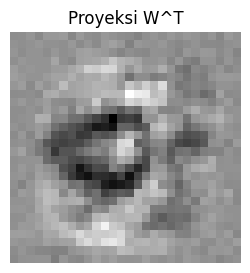

In [13]:
plt.figure(figsize=(3, 3))
plt.imshow(x_recon_wT[0].cpu().numpy(), cmap='gray')
plt.title("Proyeksi W^T")
plt.axis('off')
plt.show()

## 3. Latent Transpose Projection

In [14]:
sample_img, sample_label = next(iter(test_loader))
sample_img = sample_img[0:1].to(device) 

# forward
with torch.no_grad():
    _, z_sample, _ = mlp(sample_img)

# 2.backward (W2^T dan W1^T)
h1_latent_trans = F.relu(torch.matmul(z_sample, W2))
x_recon_zT = torch.sigmoid(torch.matmul(h1_latent_trans, W1)).view(1, 28, 28)

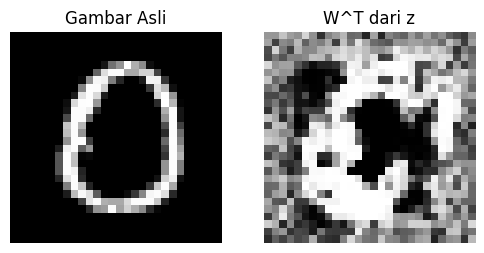

In [15]:
plt.figure(figsize=(6, 3))

# Gambar asli
plt.subplot(1, 2, 1)
plt.imshow(denorm(sample_img[0, 0]).cpu().numpy(), cmap='gray')
plt.title("Gambar Asli")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(x_recon_zT[0].cpu().numpy(), cmap='gray')
plt.title("W^T dari z")
plt.axis('off')

plt.show()

## 4. Frozen Latent Decoding
Jaringan decoder khsusus yang belajar mengkonstruksi kembali image asli dari representasi laten classifier.

### Freezing MLP Classifier Weight 
Supaya representasi laten tidak berubah

In [16]:
for param in mlp.parameters():
    param.requires_grad = False

### New Decoder (64 -> 256 -> 784)

In [17]:
class LatentDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Tanh()
        )
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

decoder_mlp = LatentDecoder().to(device)
opt_dec = torch.optim.Adam(decoder_mlp.parameters(), lr=1e-3)

### Training Decoder with MSE Loss
Dilatih untuk meminimalkan selisih piksel (Mean Squared Error) antara citra hasil tebakan decoder dengan citra asli.

In [18]:
for epoch in range(5):
    decoder_mlp.train()
    running_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        with torch.no_grad():
            _, z_feat, _ = mlp(imgs)
        
        opt_dec.zero_grad()
        rec = decoder_mlp(z_feat)
        loss = F.mse_loss(rec, imgs)
        loss.backward()
        opt_dec.step()
        running_loss += loss.item()
    print(f"Epoch [{epoch+1}/5] - Decoder MSE Loss: {running_loss / len(train_loader):.4f}")

Epoch [1/5] - Decoder MSE Loss: 0.1466
Epoch [2/5] - Decoder MSE Loss: 0.1011
Epoch [3/5] - Decoder MSE Loss: 0.0924
Epoch [4/5] - Decoder MSE Loss: 0.0874
Epoch [5/5] - Decoder MSE Loss: 0.0840


In [19]:
decoder_mlp.eval()
with torch.no_grad():
    rec_frozen_sample = decoder_mlp(z_sample)

### Comparing Result with the Real Image

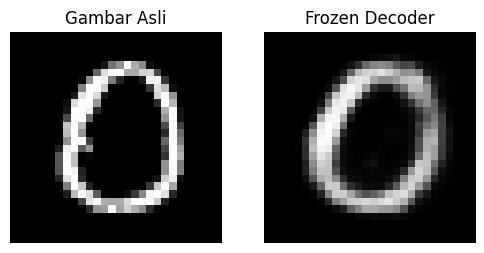

In [20]:
plt.figure(figsize=(6, 3))

# Gambar Asli
plt.subplot(1, 2, 1)
plt.imshow(denorm(sample_img[0, 0]).cpu().numpy(), cmap='gray')
plt.title("Gambar Asli")
plt.axis('off')

# Hasil Rekonstruksi dari Frozen Latent Decoder
plt.subplot(1, 2, 2)
plt.imshow(denorm(rec_frozen_sample[0, 0]).cpu().numpy(), cmap='gray')
plt.title("Frozen Decoder")
plt.axis('off')

plt.show()

## 5. Prior Sampling at Latents MLP

### Vektor laten z from test set

In [21]:
mlp_latents = []
with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        _, z_batch, _ = mlp(imgs)
        mlp_latents.append(z_batch.cpu())

mlp_latents = torch.cat(mlp_latents, dim=0)

### Mean & Standard Deviation

In [22]:
mu_z = mlp_latents.mean(dim=0)
std_z = mlp_latents.std(dim=0)

### Random Spot

In [23]:
z_rand = (mu_z + std_z * torch.randn(1, 64)).to(device)

# Decode 
with torch.no_grad():
    sample_random_mlp = decoder_mlp(z_rand)

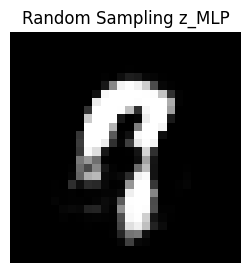

In [24]:
plt.figure(figsize=(3, 3))
plt.imshow(denorm(sample_random_mlp[0, 0]).cpu().numpy(), cmap='gray')
plt.title("Random Sampling z_MLP")
plt.axis('off')
plt.show()

# Autoencoder

3 Unsupervised architecture:
1. **Vanilla Autoencoder**: Kompresi deterministik dengan bottleneck z = 64.
2. **Sparse Autoencoder**: Ditambahkan penalti regularisasi L1 sparsity pada ruang laten.
3. **Variational Autoencoder (VAE)**: Pemodelan probabilistik z ~ N(mu, sigma^2) dengan reparameterization trick.

## Vanilla Autoencoder (z = 64) Architecture

Bertugas mengompresi citra $x$ ke ruang laten $z$ yang berdimensi lebih kecil, lalu membukanya kembali menjadi rekontruksi $\hat{x}$. 

Tujuannya murni mengukur kemiripan piksel demi piksel (pixel-wise similarity) antara citra asli $x$ dengan citra hasil rekonstruksi $\hat{x}$. Karena target piksel kontinu setelah dinormalisasi, Mean Squared Error (MSE) adalah fungsi kerugian regresi paling standar dan optimal untuk mengukur rekonstruksi.


In [25]:
class VanillaAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Tanh()
        )
    def forward(self, x):
        flat = x.view(x.size(0), -1)
        z = self.encoder(flat)
        rec = self.decoder(z)
        return rec.view(x.size(0), 1, 28, 28), z

## Sparse Autoencoder (L1 Sparsity pada Bottleneck z = 64) Architecture

Memaksa representasi laten menjadi "jarang" (sparse). Artinya, dari 64 neuron laten yang ada, hanya sebagian kecil neuron yang boleh aktif menyala untuk satu gambar tertentu.

Jika hanya menggunakan MSE biasa, model akan berperilaku seperti Vanilla AE biasa. Supaya sifat sparsitasnya muncul, ada penambahan penalti norm-$L_1$ ($\lambda \Vert{}z\Vert{}_1$).   

In [26]:
class SparseAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Tanh()
        )
    def forward(self, x):
        flat = x.view(x.size(0), -1)
        z = self.encoder(flat)
        rec = self.decoder(z)
        return rec.view(x.size(0), 1, 28, 28), z

## Variational Autoencoder (VAE) Architecture

Menjadi model generatif probabilistik, bukan sekadar kompresor data. VAE tidak memetakan gambar ke titik tetap, melainkan ke distribusi probabilitas (rata-rata $\mu$ dan varians $\sigma^2$).

Menggunakan MSE dan juga KL-Divergence yakni yang bertindak untuk memaksa distribusi laten $q(z\vert{}x)$ agar tetap mendekati distribusi normal standar 

In [27]:
class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Tanh()
        )
    def encode(self, x):
        h = F.relu(self.fc1(x.view(x.size(0), -1)))
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar, z

## Training 15 Epoch

In [28]:
import time
EPOCHS = 15

### Training Vanilla AE

In [30]:
model_v_ae = VanillaAE(latent_dim=64).to(device)
opt_v_ae = torch.optim.Adam(model_v_ae.parameters(), lr=1e-3)
loss_hist_v_ae = []
t0 = time.time()

for ep in range(EPOCHS):
    model_v_ae.train()
    running_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        opt_v_ae.zero_grad()
        rec, _ = model_v_ae(imgs)
        loss = F.mse_loss(rec, imgs)
        loss.backward()
        opt_v_ae.step()
        running_loss += loss.item() * imgs.size(0)
    avg_loss = running_loss / len(train_set)
    loss_hist_v_ae.append(avg_loss)
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"Epoch [{ep+1:02d}/{EPOCHS}] - MSE Loss: {avg_loss:.4f}")

time_v_ae = time.time() - t0
print(f"-> {time_v_ae:.1f} Seconds")

Epoch [01/15] - MSE Loss: 0.1283
Epoch [05/15] - MSE Loss: 0.0360
Epoch [10/15] - MSE Loss: 0.0295
Epoch [15/15] - MSE Loss: 0.0264
-> 112.8 Seconds


### Training Sparse AE

In [34]:
model_sae = SparseAE(latent_dim=64).to(device)
opt_sae = torch.optim.Adam(model_sae.parameters(), lr=1e-3)
loss_hist_sae = []
t0 = time.time()

for ep in range(EPOCHS):
    model_sae.train()
    running_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        opt_sae.zero_grad()
        rec, z = model_sae(imgs)
        l1_penalty = torch.mean(torch.abs(z))
        loss = F.mse_loss(rec, imgs) + 1e-3 * l1_penalty
        loss.backward()
        opt_sae.step()
        running_loss += loss.item() * imgs.size(0)
    avg_loss = running_loss / len(train_set)
    loss_hist_sae.append(avg_loss)
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"Epoch [{ep+1:02d}/{EPOCHS}] - Total Loss: {avg_loss:.4f}")
        
time_sae = time.time() - t0
print(f"-> {time_sae:.1f} Seconds")

Epoch [01/15] - Total Loss: 0.1237
Epoch [05/15] - Total Loss: 0.0386
Epoch [10/15] - Total Loss: 0.0321
Epoch [15/15] - Total Loss: 0.0286
-> 105.6 Seconds


### Training Variational AE

In [32]:
model_vae = VAE(latent_dim=64).to(device)
opt_vae = torch.optim.Adam(model_vae.parameters(), lr=1e-3)
loss_hist_vae = []
t0 = time.time()

for ep in range(EPOCHS):
    model_vae.train()
    running_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        opt_vae.zero_grad()
        rec, mu, logvar, _ = model_vae(imgs)
        rec_loss = F.mse_loss(rec, imgs, reduction='sum')
        kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        loss = (rec_loss + kl_div) / imgs.size(0)
        loss.backward()
        opt_vae.step()
        running_loss += loss.item() * imgs.size(0)
    avg_loss = running_loss / len(train_set)
    loss_hist_vae.append(avg_loss)
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"Epoch [{ep+1:02d}/{EPOCHS}] - ELBO Loss: {avg_loss:.4f}")

time_vae = time.time() - t0
print(f"-> {time_vae:.1f} Seconds")

Epoch [01/15] - ELBO Loss: 146.8561
Epoch [05/15] - ELBO Loss: 77.2957
Epoch [10/15] - ELBO Loss: 71.8365
Epoch [15/15] - ELBO Loss: 70.0716
-> 106.7 Seconds


## Reconstruction Grid

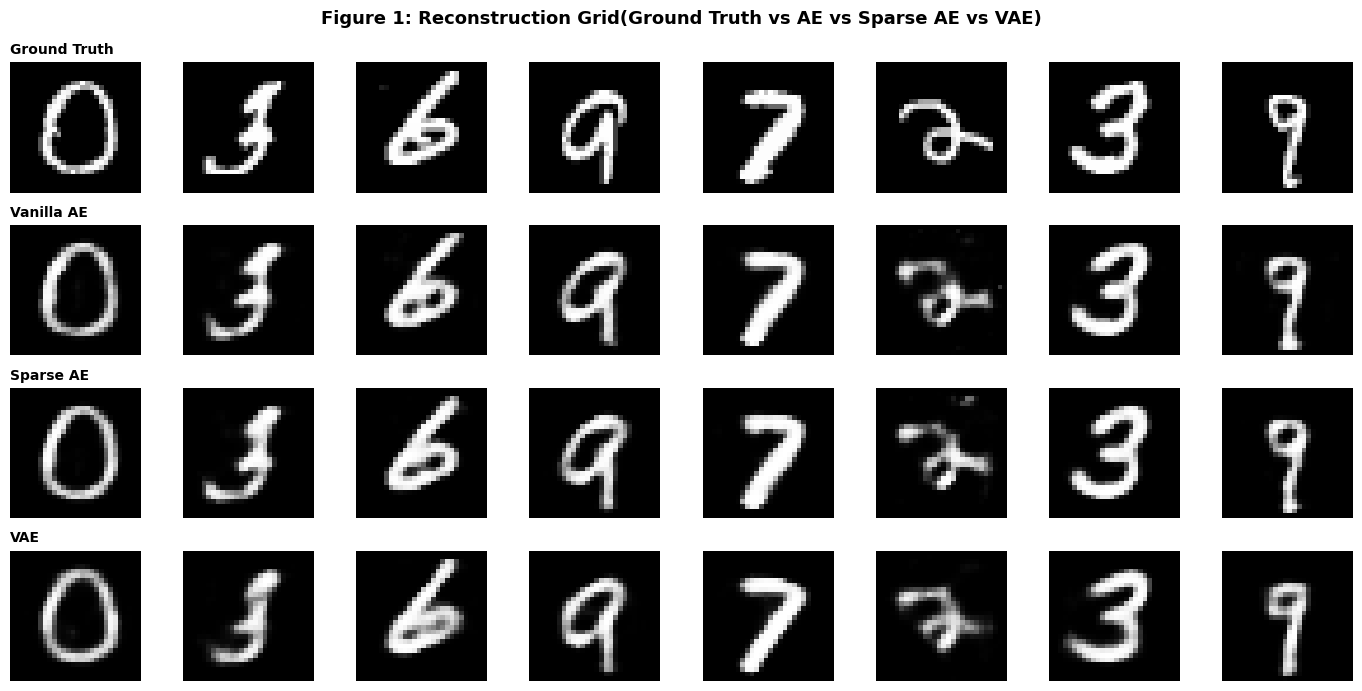

In [35]:
test_iter = iter(test_loader)
test_imgs, _ = next(test_iter)
test_samples = test_imgs[:8].to(device)

with torch.no_grad():
    rec_v_ae, _ = model_v_ae(test_samples)
    rec_s_ae, _ = model_sae(test_samples)
    rec_vae, _, _, _ = model_vae(test_samples)

fig1, axes = plt.subplots(4, 8, figsize=(14, 7))
rows = [
    ("Ground Truth", denorm(test_samples)),
    ("Vanilla AE", denorm(rec_v_ae)),
    ("Sparse AE", denorm(rec_s_ae)),
    ("VAE", denorm(rec_vae))
]

for r_idx, (name, img_tensor) in enumerate(rows):
    for c_idx in range(8):
        ax = axes[r_idx, c_idx]
        ax.imshow(img_tensor[c_idx, 0].cpu().numpy(), cmap='gray')
        ax.axis('off')
        if c_idx == 0:
            ax.set_title(name, fontsize=10, loc='left', fontweight='bold')

plt.suptitle("Figure 1: Reconstruction Grid(Ground Truth vs AE vs Sparse AE vs VAE)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("1_reconstruction_grid.png", dpi=300)
plt.show()

# GAN
Melatih dua varian model adversarial:
1. **Vanilla GAN**: Generator & Discriminator berbasis Multi-Layer Perceptron (dimensi laten noise z = 64).
2. **DCGAN (Deep Convolutional GAN)**: Generator menggunakan ConvTranspose2d + BatchNorm2d dan Discriminator menggunakan Conv2d + LeakyReLU (dimensi laten noise z = 100).

## Vanilla GAN

In [ ]:
class VanillaGenerator(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 784),
            nn.Tanh()  # Output [-1, 1] 
        )
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class VanillaDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()  # Output Prob [0, 1]
        )
    def forward(self, x):
        return self.net(x.view(x.size(0), -1))

## DCGAN

In [38]:
class DCGANGenerator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            # Input: z [Batch, 100, 1, 1] -> Output fitur 7x7
            nn.ConvTranspose2d(z_dim, 128, 7, 1, 0, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # 7x7 -> 14x14
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            # 14x14 -> 28x28
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    def forward(self, z):
        return self.net(z.view(z.size(0), z.size(1), 1, 1))

class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # 28x28 -> 14x14
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # 14x14 -> 7x7
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # 7x7 -> 1x1
            nn.Conv2d(128, 1, 7, 1, 0, bias=False),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x).view(-1, 1)

## Training 15 Epoch

### Training Vanilla GAN

In [39]:
v_gen = VanillaGenerator(z_dim=64).to(device)
v_disc = VanillaDiscriminator().to(device)

opt_v_g = torch.optim.Adam(v_gen.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_v_d = torch.optim.Adam(v_disc.parameters(), lr=2e-4, betas=(0.5, 0.999))

loss_hist_v_g, loss_hist_v_d = [], []
t0 = time.time()

for ep in range(EPOCHS):
    v_gen.train()
    v_disc.train()
    running_g, running_d = 0.0, 0.0
    
    for imgs, _ in train_loader:
        b_size = imgs.size(0)
        real_imgs = imgs.to(device)
        real_labels = torch.ones(b_size, 1).to(device)
        fake_labels = torch.zeros(b_size, 1).to(device)

        # 1. Update Discriminator: log(D(x)) + log(1 - D(G(z)))
        opt_v_d.zero_grad()
        z = torch.randn(b_size, 64, device=device)
        fake_imgs = v_gen(z)
        
        loss_d_real = F.binary_cross_entropy(v_disc(real_imgs), real_labels)
        loss_d_fake = F.binary_cross_entropy(v_disc(fake_imgs.detach()), fake_labels)
        loss_d = loss_d_real + loss_d_fake
        loss_d.backward()
        opt_v_d.step()

        # 2. Update Generator: log(D(G(z)))
        opt_v_g.zero_grad()
        loss_g = F.binary_cross_entropy(v_disc(fake_imgs), real_labels)
        loss_g.backward()
        opt_v_g.step()

        running_d += loss_d.item() * b_size
        running_g += loss_g.item() * b_size
        
    avg_d = running_d / len(train_set)
    avg_g = running_g / len(train_set)
    loss_hist_v_d.append(avg_d)
    loss_hist_v_g.append(avg_g)
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"Epoch [{ep+1:02d}/{EPOCHS}] - Loss D: {avg_d:.4f} | Loss G: {avg_g:.4f}")

time_v_gan = time.time() - t0
print(f"-> {time_v_gan:.1f} Seconds")

Epoch [01/15] - Loss D: 0.9017 | Loss G: 1.3962
Epoch [05/15] - Loss D: 0.5583 | Loss G: 3.0387
Epoch [10/15] - Loss D: 0.6246 | Loss G: 2.4248
Epoch [15/15] - Loss D: 0.7335 | Loss G: 2.0398
-> 128.2 Seconds


### Training DCGAN

In [41]:
dc_gen = DCGANGenerator(z_dim=100).to(device)
dc_disc = DCGANDiscriminator().to(device)

opt_dc_g = torch.optim.Adam(dc_gen.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_dc_d = torch.optim.Adam(dc_disc.parameters(), lr=2e-4, betas=(0.5, 0.999))

loss_hist_dc_g, loss_hist_dc_d = [], []
t0 = time.time()

for ep in range(EPOCHS):
    dc_gen.train()
    dc_disc.train()
    running_g, running_d = 0.0, 0.0
    
    for imgs, _ in train_loader:
        b_size = imgs.size(0)
        real_imgs = imgs.to(device)
        real_labels = torch.ones(b_size, 1).to(device)
        fake_labels = torch.zeros(b_size, 1).to(device)

        # 1. Update Discriminator
        opt_dc_d.zero_grad()
        z = torch.randn(b_size, 100, device=device)
        fake_imgs = dc_gen(z)
        
        loss_d_real = F.binary_cross_entropy(dc_disc(real_imgs), real_labels)
        loss_d_fake = F.binary_cross_entropy(dc_disc(fake_imgs.detach()), fake_labels)
        loss_d = loss_d_real + loss_d_fake
        loss_d.backward()
        opt_dc_d.step()

        # 2. Update Generator
        opt_dc_g.zero_grad()
        loss_g = F.binary_cross_entropy(dc_disc(fake_imgs), real_labels)
        loss_g.backward()
        opt_dc_g.step()

        running_d += loss_d.item() * b_size
        running_g += loss_g.item() * b_size
        
    avg_d = running_d / len(train_set)
    avg_g = running_g / len(train_set)
    loss_hist_dc_d.append(avg_d)
    loss_hist_dc_g.append(avg_g)
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"Epoch [{ep+1:02d}/{EPOCHS}] - Loss D: {avg_d:.4f} | Loss G: {avg_g:.4f}")

time_dcgan = time.time() - t0
print(f"-> {time_dcgan:.1f} Seconds")

Epoch [01/15] - Loss D: 0.5668 | Loss G: 2.2015
Epoch [05/15] - Loss D: 0.5778 | Loss G: 1.8730
Epoch [10/15] - Loss D: 0.6564 | Loss G: 1.8780
Epoch [15/15] - Loss D: 0.6476 | Loss G: 1.9582
-> 150.8 Seconds


## Result Visualization

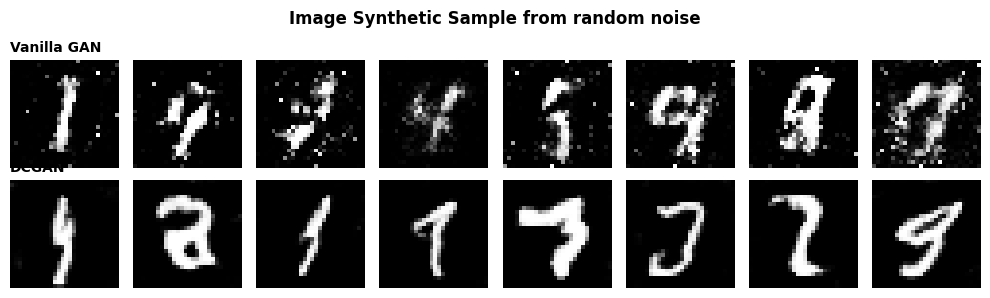

In [42]:
z_sample_v = torch.randn(8, 64, device=device)
z_sample_dc = torch.randn(8, 100, device=device)

with torch.no_grad():
    sample_vgan = denorm(v_gen(z_sample_v)).cpu()
    sample_dcgan = denorm(dc_gen(z_sample_dc)).cpu()

plt.figure(figsize=(10, 3))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(sample_vgan[i, 0].numpy(), cmap='gray')
    plt.axis('off')
    if i == 0:
        plt.title("Vanilla GAN", fontsize=10, loc='left', fontweight='bold')
        
    plt.subplot(2, 8, i + 9)
    plt.imshow(sample_dcgan[i, 0].numpy(), cmap='gray')
    plt.axis('off')
    if i == 0:
        plt.title("DCGAN", fontsize=10, loc='left', fontweight='bold')

plt.suptitle("Image Synthetic Sample from random noise", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Denoising Diffusion Probabilistic Model (DDPM)
- **Forward Process**: Penambahan noise terjadwal (variance schedule beta_t linear dari 1e-4 hingga 0.02, T = 300).
- **Reverse Backbone**: Jaringan konvolusional sederhana dengan time-step embedding (MLP).

## DDPMHelper Architecture

In [45]:
class DDPMHelper:
    def __init__(self, timesteps=300, beta_start=0.0001, beta_end=0.02):
        self.timesteps = timesteps
        self.beta = torch.linspace(beta_start, beta_end, timesteps).to(device)
        self.alpha = 1.0 - self.beta
        self.alpha_bar = torch.cumprod(self.alpha, dim=0).to(device)

    def q_sample(self, x_0, t, noise=None):
        if noise is None:
            noise = torch.randn_like(x_0)
        sqrt_alpha_bar = torch.sqrt(self.alpha_bar[t])[:, None, None, None]
        sqrt_one_minus_alpha_bar = torch.sqrt(1.0 - self.alpha_bar[t])[:, None, None, None]
        return sqrt_alpha_bar * x_0 + sqrt_one_minus_alpha_bar * noise, noise

## U-NetReverse Backbone

In [46]:
class DiffusionUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 64)
        )
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 32, 3, padding=1)
        self.out_conv = nn.Conv2d(32, 1, 3, padding=1)

    def forward(self, x, t):
        # Normalisasi ke  [-1, 1] 
        t_in = (t.float() / 300.0 * 2.0 - 1.0).unsqueeze(-1)
        t_emb = self.time_mlp(t_in).view(-1, 64, 1, 1)
        
        h = F.relu(self.conv1(x))
        h = F.relu(self.conv2(h) + t_emb)  
        h = F.relu(self.conv3(h))
        return self.out_conv(h)  

# Training 15 Epoch

In [47]:
ddpm_helper = DDPMHelper(timesteps=300)
diff_model = DiffusionUNet().to(device)
opt_diff = torch.optim.Adam(diff_model.parameters(), lr=1e-3)

loss_hist_diff = []
t0 = time.time()

for ep in range(EPOCHS):
    diff_model.train()
    running_loss = 0.0
    
    for imgs, _ in train_loader:
        b_size = imgs.size(0)
        x_0 = imgs.to(device)
        
        # 1. timesteps acak 
        t = torch.randint(0, ddpm_helper.timesteps, (b_size,), device=device).long()
        
        # 2. add noise
        x_t, noise = ddpm_helper.q_sample(x_0, t)
        
        # 3. predict
        opt_diff.zero_grad()
        pred_noise = diff_model(x_t, t)
        
        # 4. calculate MSE
        loss = F.mse_loss(pred_noise, noise)
        loss.backward()
        opt_diff.step()
        
        running_loss += loss.item() * b_size
        
    avg_loss = running_loss / len(train_set)
    loss_hist_diff.append(avg_loss)
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"Epoch [{ep+1:02d}/{EPOCHS}] - Noise Prediction MSE Loss: {avg_loss:.4f}")

time_ddpm = time.time() - t0
print(f"-> {time_ddpm:.1f} Seconds")

Epoch [01/15] - Noise Prediction MSE Loss: 0.1520
Epoch [05/15] - Noise Prediction MSE Loss: 0.0634
Epoch [10/15] - Noise Prediction MSE Loss: 0.0580
Epoch [15/15] - Noise Prediction MSE Loss: 0.0556
-> 151.1 Seconds


## Backward Checking

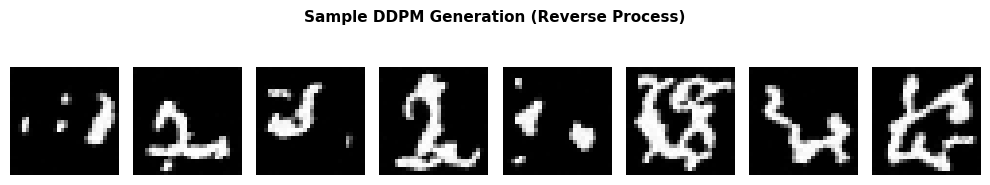

In [48]:
diff_model.eval()
with torch.no_grad():
    x_curr = torch.randn(8, 1, 28, 28, device=device)
    for step in reversed(range(0, 300)):
        t_batch = torch.full((8,), step, device=device, dtype=torch.long)
        pred_noise = diff_model(x_curr, t_batch)
        
        alpha_t = ddpm_helper.alpha[step]
        alpha_bar_t = ddpm_helper.alpha_bar[step]
        
        # Reverse sampling DDPM
        if step > 0:
            noise_z = torch.randn_like(x_curr)
        else:
            noise_z = 0
            
        sigma_t = torch.sqrt(ddpm_helper.beta[step])
        x_curr = (1 / torch.sqrt(alpha_t)) * (x_curr - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * pred_noise) + sigma_t * noise_z

sample_ddpm = denorm(x_curr).cpu()

plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(sample_ddpm[i, 0].numpy(), cmap='gray')
    plt.axis('off')
plt.suptitle("Sample DDPM Generation (Reverse Process)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()